# KEEP ancestor roll-up: expanded relationship ablation

**Question:** For the same complete patient histories and retained concept universe, how do closure edges, fixed orphan-rescue shortcuts, and target selection change patient co-occurrence relationships?

Read [the original ancestor roll-up notebook](keep_ancestor_rollup_ablation.ipynb) for hierarchy, root choice, eligibility, and scale. This notebook compares permutations and measures the changes that propagate into counts and association scores. It uses invented graph labels and histories throughout. It does not train embeddings or evaluate the KEEP model.

We proceed in order: **correctness assertions → controlled comparisons → measurements → interpretation**. Agreement with hand-derived synthetic expectations validates this experiment's plumbing. It does not establish clinical correctness, author-artifact parity, or published-result replication.

Context: [KEEP (Elhussein et al., CHIL 2025)](https://proceedings.mlr.press/v287/elhussein25a.html) and [GloVe (Pennington et al., 2014)](https://aclanthology.org/D14-1162/). The patient-level PPMI and profile comparisons here are explicit study measures. GloVe log targets and weights are inputs to its objective; computing the full loss requires learned vectors and biases.

The agreed depth-five, two-diagnosis, root-exclusive `all_retained` baseline and its single-parent/root-inclusive variants are in the [baseline and roll-up variants notebook](keep_ancestor_rollup_variants.ipynb). This closure/rescue experiment remains a separate extension.

### Run this notebook

Use a Python 3.12+ environment with this KEEP-enabled PyHealth checkout and graph dependencies installed. From the repository root:

```sh
python -m pip install -e '.[graph]'
python -m pip install pandas matplotlib nbformat nbclient nbconvert ipykernel
```

Select that environment as the notebook kernel and run all cells. No Athena or patient files are required. The helpers live beside this notebook; they use the real `AncestorRollupProcessor` and an explicitly labeled independent example counter. The companion baseline/variants notebook checks its counts against the public KEEP counter; reader and ICD-mapping integration have their own tests.

In [1]:
from pathlib import Path
import hashlib
import inspect
import subprocess
import sys
import warnings

warnings.filterwarnings("ignore", message="`torch.jit.script` is deprecated.*", category=FutureWarning)
warnings.filterwarnings("ignore", message="IProgress not found.*")
ROOT = Path.cwd().parent if Path.cwd().name == "examples" else Path.cwd()
if not (ROOT / "examples" / "keep_ancestor_rollup_ablation_utils.py").is_file():
    raise RuntimeError("Run with the repository root or examples/ as the working directory")
sys.path.insert(0, str(ROOT))

import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import display
from examples.keep_ancestor_rollup_ablation_utils import (
    ARMS, AXES, CLOSURE_ONLY, DEPTHS, DIRECT, RESCUE, arm_name,
    assert_fixture, compare_matrices, count_histories, expected_targets,
    make_processors, one_factor_contrasts, run_experiment,
    synthetic_histories, trace_pair, validate_matrix,
)
from pyhealth.processors import AncestorRollupProcessor

print("Python:", sys.version.split()[0])
print("Checkout commit:", subprocess.check_output(["git", "rev-parse", "HEAD"], cwd=ROOT, text=True).strip())
print("Processor SHA256:", hashlib.sha256(Path(inspect.getfile(AncestorRollupProcessor)).read_bytes()).hexdigest())

Python: 3.12.12
Checkout commit: 3c86e39dd3b1ba0a7e59a858bad77db9247ab5fb
Processor SHA256: a24e881f4ec42383b9fedd2ece468c7637d9eb5f6d3cd283664aa0e31331947e


## 1. Fixed inputs and eight policy permutations

A target is present for a patient after **two distinct diagnoses** map to it across the complete history. Union targets within each diagnosis, collapse identical copies of its identity, and reject conflicting copies. Each patient contributes once to each pair of present targets; include both triangles and prevalence diagonals. Keep all nine patients, including empty and unmapped histories, in the common denominator.

Our 2 × 2 × 2 design changes:

| Factor | Off / baseline | On / comparison |
|---|---|---|
| Target selection | `first_retained`: first eligible ancestor on each upward branch | `all_retained`: every eligible ancestor |
| Closure overlay | Direct parent-to-child edges | Add fixed separation-one pair `C2 → X` |
| Rescue construction | Keep orphan `O` disconnected | Add fixed shortcut `A2 → O` |

Hold root `R`, cutoff **2**, root exclusion, supplied root depths, concept IDs, histories, presence threshold, and GloVe comparison settings fixed. The smaller cutoff keeps the fixture readable; it is not a change to the original notebook's cutoff-five study.

```
R → A1 → A2 → A3 → X
R → B1 → B2 → B3 → X
R → C1 → C2   ─ ─ → X    closure-only edge
         A2   ─ ─ → O    fixed rescue edge
Z                         retained isolate; no diagnosis uses it
```

The supplied minimum depth of `X` is 3, consistent with the closure path through `C2`; its direct paths have length 4. `O` has supplied depth 3, and `Z` depth 2. Eligibility stays fixed when edges change. This models disagreement between depth and adjacency sources. The rescue arm adds an explicit synthetic edge set frozen across closure arms; it does not claim to run the Athena reader's orphan-selection algorithm or expose a public factory rescue setting.

In [2]:
histories = synthetic_histories()
processors = make_processors()
arm_table = pd.DataFrame([
    {"arm": arm_name(arm), "policy": arm[0], "closure": arm[1], "rescue": arm[2],
     "X_targets_expected": sorted(expected_targets(arm)[0]),
     "O_targets_expected": sorted(expected_targets(arm)[1])}
    for arm in ARMS
])
display(arm_table)
display(pd.DataFrame([{"patient": h["patient_id"], "diagnoses": h["diagnoses"]} for h in histories]))
display(pd.DataFrame([{"concept": c, "supplied_depth": d, "retained": c in AXES} for c, d in DEPTHS.items()]))

,arm,policy,closure,rescue,X_targets_expected,O_targets_expected
0,first_retained|closure=0|rescue=0,first_retained,False,False,"[A2, B2]",[]
1,first_retained|closure=0|rescue=1,first_retained,False,True,"[A2, B2]",[A2]
2,first_retained|closure=1|rescue=0,first_retained,True,False,"[A2, B2, C2]",[]
3,first_retained|closure=1|rescue=1,first_retained,True,True,"[A2, B2, C2]",[A2]
4,all_retained|closure=0|rescue=0,all_retained,False,False,"[A1, A2, B1, B2]",[]
5,all_retained|closure=0|rescue=1,all_retained,False,True,"[A1, A2, B1, B2]","[A1, A2]"
6,all_retained|closure=1|rescue=0,all_retained,True,False,"[A1, A2, B1, B2, C1, C2]",[]
7,all_retained|closure=1|rescue=1,all_retained,True,True,"[A1, A2, B1, B2, C1, C2]","[A1, A2]"


,patient,diagnoses
0,p1,"[{'diagnosis_id': 'x1', 'codes': ['X']}, {'dia..."
1,p2,"[{'diagnosis_id': 'x1', 'codes': ['X']}, {'dia..."
2,p3,"[{'diagnosis_id': 'o1', 'codes': ['O']}, {'dia..."
3,p4,"[{'diagnosis_id': 'copy', 'codes': ['X']}, {'d..."
4,p5,"[{'diagnosis_id': 'a1', 'codes': ['A2']}, {'di..."
5,p6,[]
6,p7,"[{'diagnosis_id': 'multi', 'codes': ['X', 'O']..."
7,p8,"[{'diagnosis_id': 'c1', 'codes': ['C2']}, {'di..."
8,p9,"[{'diagnosis_id': 'o1', 'codes': ['O']}, {'dia..."


,concept,supplied_depth,retained
0,R,0,False
1,A1,1,True
2,A2,2,True
3,A3,3,False
4,B1,1,True
5,B2,2,True
6,B3,3,False
7,C1,1,True
8,C2,2,True
9,X,3,False


## 2. Correctness before measurement

Check every arm against target sets derived by hand. Expected patient presence is also explicit: `p1 = targets(X) ∪ {C2}`, `p2 = targets(X)`, `p3 = targets(O) ∪ {B2}`, `p5 = {A2,B2}`, `p8 = {A2,C2}`, and `p9 = targets(O)`. Patients `p4`, `p6`, and `p7` have no present targets: a copied diagnosis or one diagnosis mapping to several concepts cannot meet the two-diagnosis threshold.

Assert all 49 matrix coordinates against the expected patient sets, rather than deriving expectations from the measured matrix. Preserve the zero row for `Z`. These assertions must pass in every arm before interpreting a difference between arms.

In [3]:
matrices, traces = {}, {}
for name, processor in processors.items():
    matrices[name], traces[name] = count_histories(processor, histories)
assert_fixture(processors, matrices, traces)

baseline = arm_name(("first_retained", False, False))
base_values = validate_matrix(matrices[baseline])
assert base_values["A2", "B2"] == 3   # p1, p2, p5
assert base_values["A2", "A2"] == 4   # p1, p2, p5, p8
assert base_values["B2", "B2"] == 4   # p1, p2, p3, p5
assert matrices[baseline]["patients"] == 9
print("Passed: eight target/presence checks and all matrix coordinates; common axes retain Z.")

Passed: eight target/presence checks and all matrix coordinates; common axes retain Z.


In [4]:
# Row order must not change counts. Conflicting copies must fail explicitly.
reordered = [dict(h, diagnoses=list(reversed(h["diagnoses"]))) for h in reversed(histories)]
for name, processor in processors.items():
    assert count_histories(processor, reordered)[0] == matrices[name]

invalid = [{"patient_id": "synthetic-conflict", "diagnoses": [
    {"diagnosis_id": "same", "codes": ["X"]},
    {"diagnosis_id": "same", "codes": ["O"]},
]}]
try:
    count_histories(processors[baseline], invalid)
except ValueError as exc:
    assert "conflicting copies" in str(exc)
else:
    raise AssertionError("Conflicting diagnosis copies were accepted")
print("Passed: row permutation and deliberate identity corruption checks.")

Passed: row permutation and deliberate identity corruption checks.


## 3. Controlled comparisons and a diagnosis-to-count trace

Compute all **28 unordered arm comparisons**. Start interpretation with the **12 contrasts that change one factor**, holding the other two fixed. These form the edges of the factorial cube. A multi-factor comparison is descriptive and can combine several mechanisms.

The table separates changes in raw counts from changes in PPMI. PPMI may change even when a pair count stays fixed, because its marginal prevalences change. Undefined PPMI deltas remain explicitly counted.

In [5]:
experiment = run_experiment()  # Same orchestration as the headless command.
assert experiment["matrices"] == matrices
assert len(experiment["comparisons"]) == 28
assert len(experiment["controlled_contrasts"]) == 12
controlled = pd.DataFrame(experiment["controlled_contrasts"])
display(controlled)

,factor,before,after,observed_pair_union,changed_count_pairs,gained_pairs,lost_pairs,absolute_count_delta,changed_ppmi_pairs,undefined_ppmi_deltas
0,target_policy,first_retained|closure=0|rescue=0,all_retained|closure=0|rescue=0,10,7,7,0,12,0,7
1,target_policy,first_retained|closure=0|rescue=1,all_retained|closure=0|rescue=1,10,7,7,0,15,0,7
2,target_policy,first_retained|closure=1|rescue=0,all_retained|closure=1|rescue=0,15,12,12,0,24,0,12
3,target_policy,first_retained|closure=1|rescue=1,all_retained|closure=1|rescue=1,15,12,12,0,27,0,12
4,closure,first_retained|closure=0|rescue=0,first_retained|closure=1|rescue=0,3,2,0,0,2,1,0
5,closure,first_retained|closure=0|rescue=1,first_retained|closure=1|rescue=1,3,2,0,0,2,1,0
6,closure,all_retained|closure=0|rescue=0,all_retained|closure=1|rescue=0,15,9,5,0,14,3,5
7,closure,all_retained|closure=0|rescue=1,all_retained|closure=1|rescue=1,15,9,5,0,14,3,5
8,rescue,first_retained|closure=0|rescue=0,first_retained|closure=0|rescue=1,3,1,0,0,1,2,0
9,rescue,first_retained|closure=1|rescue=0,first_retained|closure=1|rescue=1,3,1,0,0,1,2,0


In [6]:
# Edit these names to inspect any pair of the eight arms.
BEFORE = arm_name(("all_retained", False, False))
AFTER = arm_name(("all_retained", True, False))
report = compare_matrices(matrices[BEFORE], matrices[AFTER], x_max=50, alpha=0.75)
pair_rows = pd.json_normalize(report["pairs"])
display(pair_rows.loc[pair_rows["count_delta"].ne(0), [
    "i", "j", "status", "before.count", "after.count", "count_delta",
    "before.prevalence_i", "after.prevalence_i", "before.prevalence_j", "after.prevalence_j",
]])

,i,j,status,before.count,after.count,count_delta,before.prevalence_i,after.prevalence_i,before.prevalence_j,after.prevalence_j
3,A1,C1,gained,0,2,2,2,2,0,2
4,A1,C2,shared,1,2,1,2,2,2,3
7,A2,C1,gained,0,2,2,4,4,0,2
8,A2,C2,shared,2,3,1,4,4,2,3
10,B1,C1,gained,0,2,2,2,2,0,2
11,B1,C2,shared,1,2,1,2,2,2,3
12,B2,C1,gained,0,2,2,4,4,0,2
13,B2,C2,shared,1,2,1,4,4,2,3
14,C1,C2,gained,0,2,2,0,2,2,3


For `A2,C2`, enabling closure lets the two distinct `X` diagnoses of `p2` establish `C2`. Patient `p1` already has two retained `C2` diagnoses, so its contribution to this pair stays unchanged. The following trace shows the actual diagnosis results and reconciles the changed patient contributions with the matrix delta.

In [7]:
# Fixed worked trace; the measurement contrast above remains independently selectable.
PAIR = ("A2", "C2")
TRACE_BEFORE = arm_name(("all_retained", False, False))
TRACE_AFTER = arm_name(("all_retained", True, False))
witnesses = trace_pair(traces[TRACE_BEFORE], traces[TRACE_AFTER], *PAIR)
a = validate_matrix(matrices[TRACE_BEFORE]).get(PAIR, 0)
b = validate_matrix(matrices[TRACE_AFTER]).get(PAIR, 0)
assert sum(w["pair_delta"] for w in witnesses) == b - a
assert (a, b) == (2, 3)
trace_rows = []
for witness in witnesses:
    for side in ("before", "after"):
        patient = witness[side]
        for diagnosis in patient["diagnoses"]:
            trace_rows.append({"patient": witness["patient_id"], "arm": side,
                               "diagnosis": diagnosis["diagnosis_id"], "source_codes": diagnosis["codes"],
                               "targets": diagnosis["targets"], "target_occurrences": patient["occurrences"],
                               "present": patient["present"], "pair_delta": witness["pair_delta"]})
display(pd.DataFrame(trace_rows))
print(f"Pair {PAIR}: {a} → {b}; reconciled patient delta = {b-a}.")

,patient,arm,diagnosis,source_codes,targets,target_occurrences,present,pair_delta
0,p2,before,x1,[X],"[A1, A2, B1, B2]","{'A1': 2, 'A2': 2, 'B1': 2, 'B2': 2}","[A1, A2, B1, B2]",1
1,p2,before,x2,[X],"[A1, A2, B1, B2]","{'A1': 2, 'A2': 2, 'B1': 2, 'B2': 2}","[A1, A2, B1, B2]",1
2,p2,after,x1,[X],"[A1, A2, B1, B2, C1, C2]","{'A1': 2, 'A2': 2, 'B1': 2, 'B2': 2, 'C1': 2, ...","[A1, A2, B1, B2, C1, C2]",1
3,p2,after,x2,[X],"[A1, A2, B1, B2, C1, C2]","{'A1': 2, 'A2': 2, 'B1': 2, 'B2': 2, 'C1': 2, ...","[A1, A2, B1, B2, C1, C2]",1


Pair ('A2', 'C2'): 2 → 3; reconciled patient delta = 1.


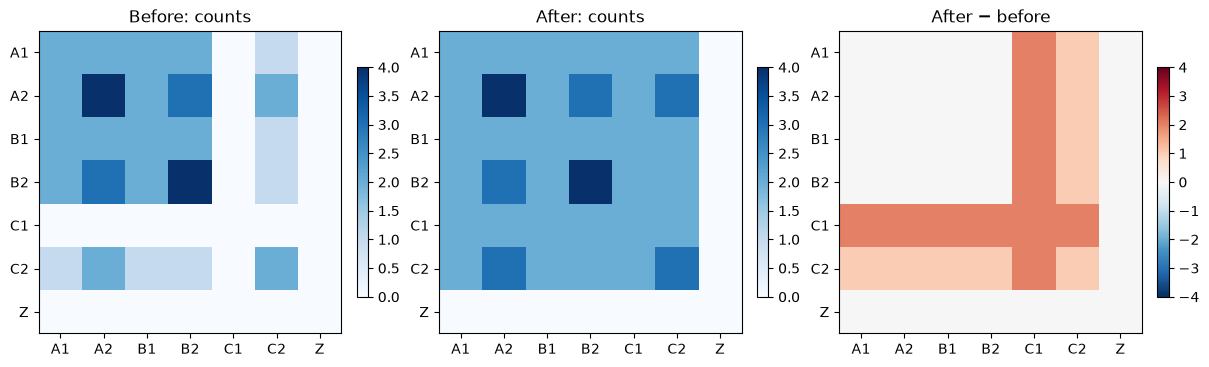

In [8]:
def dense_frame(matrix):
    values = validate_matrix(matrix)
    return pd.DataFrame([[values.get((i, j), 0) for j in AXES] for i in AXES], index=AXES, columns=AXES)

left, right = dense_frame(matrices[BEFORE]), dense_frame(matrices[AFTER])
fig, plots = plt.subplots(1, 3, figsize=(12, 3.6), constrained_layout=True)
limit = max(left.to_numpy().max(), right.to_numpy().max(), 1)
for axis, frame, title in zip(plots, (left, right, right-left), ("Before: counts", "After: counts", "After − before")):
    delta = title.startswith("After −")
    image = axis.imshow(frame, cmap="RdBu_r" if delta else "Blues", vmin=-limit if delta else 0, vmax=limit)
    axis.set(xticks=range(len(AXES)), yticks=range(len(AXES)), xticklabels=AXES, yticklabels=AXES, title=title)
    fig.colorbar(image, ax=axis, shrink=0.7)
plt.show()
# Diagonals in this figure show prevalence; the association/profile tables below exclude them.

## 4. Measurements: definitions and interpretation

Let $X_{ij}$ be the number of patients with both targets present, $X_{ii}$ the prevalence of target $i$, and $N=9$ the fixed cohort size. Each table row represents one unordered off-diagonal pair from the union of observed pairs across the two arms. Both directional conditional probabilities are retained.

| Measure | Definition | Why measure it? |
|---|---|---|
| Raw count | $X_{ij}$ and after minus before | Direct patient contribution and the easiest hand check |
| GloVe log target | $\ln X_{ij}$ for $X_{ij}>0$ | Change in a target supplied to the training objective |
| GloVe weight | $\min((X_{ij}/x_{\max})^\alpha,1)$ | Change in relative emphasis under fixed objective settings |
| Patient PPMI | $\max(0,\ln[NX_{ij}/(X_{ii}X_{jj})])$ | Positive association relative to independent patient prevalences |
| Conditional probabilities | $P(j\mid i)=X_{ij}/X_{ii}$ and $P(i\mid j)=X_{ij}/X_{jj}$ | Fraction of patients with one concept who also have the other |
| Row cosine | $u\cdot v/(\|u\|\|v\|)$, separately for count and PPMI profiles | Whether the relationship profile points in a similar direction |
| Row JSD | $\tfrac12 KL_2(p\|m)+\tfrac12 KL_2(q\|m)$; $m=(p+q)/2$ | Change in profile mass after each nonnegative row is normalized |
| Concentration | Top $\lceil0.01K\rceil$ observed-pair mass share; $HHI=\sum_k s_k^2$ | Whether count mass is concentrated in a small number of relationships |

**Conventions:** natural logarithms for count targets and PPMI; base-2 JSD divergence in [0,1], not the square-root distance. A zero count has no log target or log delta. For PPMI, zero count with positive marginals is assigned 0 by convention; zero marginal gives an undefined value. Conditional probabilities are undefined when their conditioning prevalence is zero. Reports use `None`/JSON `null` for undefined values (Pandas may display NaN). No pseudocount, rare-count filter, normalization, or weighting changes the raw matrix.

Profiles exclude diagonals and preserve the common concept axis. Undefined PPMI coordinates contribute zero mass to a profile, while their pair-level undefined status remains visible. An all-zero row makes cosine and JSD undefined. Cosine can equal 1 and JSD 0 under uniform scaling even when count deltas are large, so inspect support and count deltas alongside them.

We fix $x_{\max}=50$ and $\alpha=0.75$ in both arms for a controlled weighting comparison. These are declared study settings, not a claim that the KEEP trainer uses a fixed cutoff on every cohort. The earlier implementation audit observed an adaptive cutoff in the local trainer; no embeddings, biases, regularization, full loss, or predictive performance are evaluated here.

In [9]:
score_columns = ["i", "j", "status", "before.count", "after.count", "count_delta",
                 "before.log_count", "after.log_count", "log_count_delta",
                 "before.glove_weight", "after.glove_weight", "glove_weight_delta",
                 "before.ppmi", "after.ppmi", "ppmi_delta",
                 "before.p_j_given_i", "after.p_j_given_i", "p_j_given_i_delta",
                 "before.p_i_given_j", "after.p_i_given_j", "p_i_given_j_delta"]
display(pair_rows[score_columns].round(5))
# Inspect the largest absolute PPMI deltas with both raw support and marginals.
display(pair_rows.assign(abs_ppmi_delta=pair_rows["ppmi_delta"].abs())
        .sort_values("abs_ppmi_delta", ascending=False)
        [["i", "j", "before.count", "after.count", "before.prevalence_i", "after.prevalence_i",
          "before.prevalence_j", "after.prevalence_j", "ppmi_delta"]].head(8).round(5))

,i,j,status,before.count,after.count,count_delta,before.log_count,after.log_count,log_count_delta,before.glove_weight,...,glove_weight_delta,before.ppmi,after.ppmi,ppmi_delta,before.p_j_given_i,after.p_j_given_i,p_j_given_i_delta,before.p_i_given_j,after.p_i_given_j,p_i_given_j_delta
0,A1,A2,shared,2,2,0,0.69315,0.69315,0.00000,0.08944,...,0.00000,0.81093,0.81093,0.00000,1.00,1.00,0.00,0.50,0.50000,0.00000
1,A1,B1,shared,2,2,0,0.69315,0.69315,0.00000,0.08944,...,0.00000,1.50408,1.50408,0.00000,1.00,1.00,0.00,1.00,1.00000,0.00000
2,A1,B2,shared,2,2,0,0.69315,0.69315,0.00000,0.08944,...,0.00000,0.81093,0.81093,0.00000,1.00,1.00,0.00,0.50,0.50000,0.00000
3,A1,C1,gained,0,2,2,NaN,0.69315,NaN,0.00000,...,0.08944,NaN,1.50408,NaN,0.00,1.00,1.00,NaN,1.00000,NaN
4,A1,C2,shared,1,2,1,0.00000,0.69315,0.69315,0.05318,...,0.03626,0.81093,1.09861,0.28768,0.50,1.00,0.50,0.50,0.66667,0.16667
5,A2,B1,shared,2,2,0,0.69315,0.69315,0.00000,0.08944,...,0.00000,0.81093,0.81093,0.00000,0.50,0.50,0.00,1.00,1.00000,0.00000
6,A2,B2,shared,3,3,0,1.09861,1.09861,0.00000,0.12123,...,0.00000,0.52325,0.52325,0.00000,0.75,0.75,0.00,0.75,0.75000,0.00000
7,A2,C1,gained,0,2,2,NaN,0.69315,NaN,0.00000,...,0.08944,NaN,0.81093,NaN,0.00,0.50,0.50,NaN,1.00000,NaN
8,A2,C2,shared,2,3,1,0.69315,1.09861,0.40547,0.08944,...,0.03179,0.81093,0.81093,0.00000,0.50,0.75,0.25,1.00,1.00000,0.00000
9,B1,B2,shared,2,2,0,0.69315,0.69315,0.00000,0.08944,...,0.00000,0.81093,0.81093,0.00000,1.00,1.00,0.00,0.50,0.50000,0.00000


,i,j,before.count,after.count,before.prevalence_i,after.prevalence_i,before.prevalence_j,after.prevalence_j,ppmi_delta
4,A1,C2,1,2,2,2,2,3,0.28768
11,B1,C2,1,2,2,2,2,3,0.28768
13,B2,C2,1,2,4,4,2,3,0.28768
0,A1,A2,2,2,2,2,4,4,0.00000
1,A1,B1,2,2,2,2,2,2,0.00000
2,A1,B2,2,2,2,2,4,4,0.00000
5,A2,B1,2,2,4,4,2,2,0.00000
6,A2,B2,3,3,4,4,4,4,0.00000


In [10]:
profiles = pd.DataFrame(report["profiles"])
display(profiles.round(5))
assert profiles.loc[profiles["concept_id"].eq("Z"), ["count_cosine", "count_jsd", "ppmi_cosine", "ppmi_jsd"]].isna().all().all()

concentration_rows = []
for name, matrix in matrices.items():
    measures = compare_matrices(matrix, matrix)["concentration"]["before"]
    concentration_rows.append({"arm": name, **measures})
concentration_table = pd.DataFrame(concentration_rows)
display(concentration_table.round(5))

,concept_id,count_cosine,count_jsd,ppmi_cosine,ppmi_jsd
0,A1,0.86824,0.11990,0.81795,0.14816
1,A2,0.91634,0.09398,0.87953,0.11703
2,B1,0.86824,0.11990,0.81795,0.14816
3,B2,0.89567,0.10837,0.83260,0.15268
4,C1,NaN,NaN,NaN,NaN
5,C2,0.90711,0.10058,0.83716,0.14806
6,Z,NaN,NaN,NaN,NaN


,arm,observed_pairs,possible_pairs,pair_mass,top_pair_count,top_1pct_share,hhi
0,first_retained|closure=0|rescue=0,3,21,6,1,0.50000,0.38889
1,first_retained|closure=0|rescue=1,3,21,7,1,0.57143,0.42857
2,first_retained|closure=1|rescue=0,3,21,8,1,0.37500,0.34375
3,first_retained|closure=1|rescue=1,3,21,9,1,0.44444,0.35802
4,all_retained|closure=0|rescue=0,10,21,18,1,0.16667,0.11111
5,all_retained|closure=0|rescue=1,10,21,22,1,0.18182,0.12397
6,all_retained|closure=1|rescue=0,15,21,32,1,0.09375,0.06836
7,all_retained|closure=1|rescue=1,15,21,36,1,0.11111,0.07253


Concentration counts **positive unordered off-diagonal pairs** once. $K$ is the observed-pair count, and $s_k$ is that pair's share of total pair-count mass. Report the possible-pair denominator, observed $K$, selected top-pair count, and total mass alongside the scores. In this tiny fixture, the "top 1%" usually means just the top one pair. HHI and the top share can also change because the number of observed pairs changes.

Variance across relationship deltas and patient resampling were considered in the earlier design discussion. We do not use either as primary evidence here: sparse pair deltas share patients and concepts, and interpreting population uncertainty would require a separate sampling and record-completeness study. These results are deterministic descriptions of the supplied histories.

## 5. Interactions, reproducibility, and limits

For each target policy, compare the closure effect with rescue off against the closure effect with rescue on. The per-pair difference in differences is

$$[X_{closure,rescue}-X_{direct,rescue}]-[X_{closure,no\ rescue}-X_{direct,no\ rescue}].$$

A nonzero value shows that the two construction choices interact for these histories. It does not establish a population or clinical causal effect. This table includes zero results so that absence of an interaction is visible.

In [11]:
interaction_rows = []
for policy in ("first_retained", "all_retained"):
    values = {(closure, rescue): validate_matrix(matrices[arm_name((policy, closure, rescue))])
              for closure in (False, True) for rescue in (False, True)}
    for index, i in enumerate(AXES):
        for j in AXES[index+1:]:
            pair = (i, j)
            no_rescue = values[True, False].get(pair, 0) - values[False, False].get(pair, 0)
            with_rescue = values[True, True].get(pair, 0) - values[False, True].get(pair, 0)
            interaction_rows.append({"policy": policy, "i": i, "j": j,
                                     "closure_delta_without_rescue": no_rescue,
                                     "closure_delta_with_rescue": with_rescue,
                                     "difference_in_differences": with_rescue-no_rescue})
interactions = pd.DataFrame(interaction_rows)
display(interactions)
print("Nonzero synthetic closure×rescue interactions:", interactions["difference_in_differences"].ne(0).sum())
print("Fixture digest:", experiment["histories_sha256"])
print("Completed: 8 asserted arms, 28 comparisons, 12 one-factor contrasts.")

,policy,i,j,closure_delta_without_rescue,closure_delta_with_rescue,difference_in_differences
0,first_retained,A1,A2,0,0,0
1,first_retained,A1,B1,0,0,0
2,first_retained,A1,B2,0,0,0
3,first_retained,A1,C1,0,0,0
4,first_retained,A1,C2,0,0,0
5,first_retained,A1,Z,0,0,0
6,first_retained,A2,B1,0,0,0
7,first_retained,A2,B2,0,0,0
8,first_retained,A2,C1,0,0,0
9,first_retained,A2,C2,1,1,0


Nonzero synthetic closure×rescue interactions: 0
Fixture digest: dc8bb34d51da81b3dbf67a42d7fae518153d50d263780f861765a8c81f721174
Completed: 8 asserted arms, 28 comparisons, 12 one-factor contrasts.


### What this run supports

The fixture proves that edge and target-policy changes can propagate through diagnosis target unions and the two-diagnosis threshold into patient prevalence, pair counts, and derived relationship scores. The tables quantify that propagation for these invented histories. Equal results in one contrast are a valid observation; they are not evidence that the settings are interchangeable on another cohort.

A cohort experiment must supply the same authorized histories to every arm, pin the vocabulary release and source revisions, hold cohort membership and counting rules fixed, and preserve the same axes including zero rows. It should report support with association changes and trace selected differences before interpreting them. This notebook neither discovers nor reads those inputs. Real patient traces and cohort-derived results belong in the human-approved storage location.

### Repeat headlessly

From the repository root and the same Python environment, choose a **new** output directory:

```sh
python -m examples.keep_ancestor_rollup_ablation_utils --output /tmp/keep-expanded-new-run
python -m unittest discover -s tests/core -p test_keep_rollup_ablation_example.py -v
python -m nbconvert --to notebook --execute examples/keep_ancestor_rollup_ablation_expanded.ipynb --output keep-expanded-executed.ipynb --output-dir /tmp --ExecutePreprocessor.timeout=180
```

The first command runs the same assertions and comparisons and writes `report.json`, including all matrices, synthetic diagnosis/presence traces, 28 pairwise reports, 12 controlled summaries, fixed settings, and input/processor digests. It refuses an existing output directory. Equality assertions are not swallowed; the deliberate conflicting-copy check is the only expected failure caught in the notebook.